# 1. From raster pixels to segment objects

Compare segmentation algorithms, turn a label image into georeferenced
polygons, attach measurements, and export raster and vector results.

This notebook runs independently with the small Chesapeake sample included in
OBIA. No data download is needed. From a repository checkout, install
`python -m pip install -e ".[notebooks]"`, then launch `jupyter lab`.
See the [sample data and setup guide](https://obia.sefa.ai/examples/) for
provenance, class codes, and source terms.

Run the cells from top to bottom. Files go into this notebook's subdirectory of
`example_outputs/`; rerunning replaces those example files. All OBIA band selections
use **zero-based numeric indices** into the loaded raster.

[Download this notebook](01_segmentation.ipynb)

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

from obia.datasets import chesapeake_sample
from obia.handlers.geotif import open_geotiff
from obia.features import extract_features
from obia.segmentation import create_labels, labels_to_segments
from skimage.segmentation import mark_boundaries

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11})
output_dir = Path("example_outputs") / "01_segmentation"
output_dir.mkdir(parents=True, exist_ok=True)

## Load the sample imagery

The bundled training crop contains real aerial imagery and an aligned land-cover
reference map. It is 1024 × 1024 pixels at 1 m resolution in EPSG:26918.
Band values are stored as unsigned bytes, from 0 to 255, rather than calibrated
reflectance. We retain bands in their original order, indexed 0–3.

`open_geotiff()` returns OBIA's `Image` class: an array plus its CRS, transform,
and pixel-validity mask. Its optional `bands=` argument uses Rasterio's one-based
file numbering; subsequent OBIA selections are zero-based.

In [2]:
sample = chesapeake_sample("train")
image = open_geotiff(sample["image"])
image.rasterio_obj.close()  # Loaded arrays and spatial metadata remain available.
with rasterio.open(sample["reference"]) as src:
    reference = src.read(1)
class_names = sample["class_names"]
print(f"Loaded array: {image.img_data.shape}; CRS: {image.crs}")
print(f"Source tile: {sample['metadata']['tile_id']}")

Loaded array: (1024, 1024, 4); CRS: EPSG:26918
Source tile: m_3807625_sw_18_1


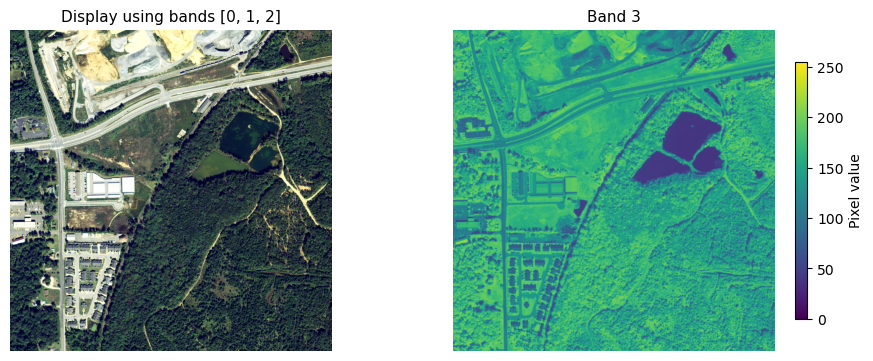

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
axes[0].imshow(image.to_image([0, 1, 2]))
axes[0].set_title("Display using bands [0, 1, 2]")
band = axes[1].imshow(image.img_data[:, :, 3], cmap="viridis", vmin=0, vmax=255)
axes[1].set_title("Band 3")
fig.colorbar(band, ax=axes[1], label="Pixel value", shrink=0.8)
for ax in axes:
    ax.set_axis_off()
plt.show()

## Compare segment boundaries

Segmentation uses imagery alone; the reference map does not define the objects.
OBIA scales selected bands to 0–1 for segmentation while keeping the source
values unchanged for feature extraction. These parameters illustrate different
boundary patterns; they are not interchangeable settings across methods.

The yellow lines mark the object boundaries. Inspect them against the imagery
and adjust parameters for the sizes and shapes you want to represent.

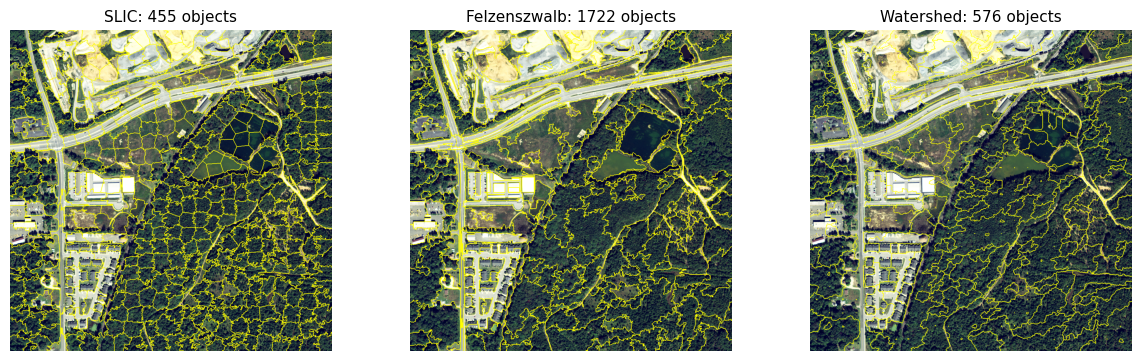

In [4]:
labels_by_method = {
    "SLIC": create_labels(
        image, segmentation_bands=[0, 1, 2, 3], method="slic",
        n_segments=600, compactness=0.3, sigma=0.6, convert2lab=False,
    ),
    "Felzenszwalb": create_labels(
        image, segmentation_bands=[0, 1, 2], method="felzenszwalb",
        scale=150, sigma=0.8, min_size=500,
    ),
    "Watershed": create_labels(
        image, segmentation_bands=[3], method="watershed", markers=600,
    ),
}

display_image = np.asarray(image.to_image([0, 1, 2]))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
for ax, (name, labels) in zip(axes, labels_by_method.items()):
    ax.imshow(mark_boundaries(display_image, labels, color=(1, 1, 0), mode="inner"))
    ax.set_title(f"{name}: {np.unique(labels[labels > 0]).size} objects")
    ax.set_axis_off()
plt.show()

## Convert labels into objects

The label array stores an integer segment ID for each pixel; 0 is background.
`labels_to_segments()` turns positive IDs into polygon rows in the raster CRS.
Adding features keeps those IDs and geometries. A segment object is a row with
its geometry and measurements, not a separate kind of model input.

In [5]:
labels = labels_by_method["SLIC"]
polygons = labels_to_segments(labels, image)
objects = extract_features(
    polygons, image, bands=[0, 1, 2, 3],
    spectral=("mean", "std"), percentiles=(), shape=("area",),
)
print(f"{len(objects)} objects; shape_area is in square metres")
objects[["segment_id", "b0_mean", "b3_mean", "shape_area", "geometry"]].head()

455 objects; shape_area is in square metres


,segment_id,b0_mean,b3_mean,shape_area,geometry
0,12,173.333653,110.245446,1043.0,"POLYGON ((328037 4269825, 328037 4269824, 3280..."
1,6,125.361314,156.865876,1096.0,"POLYGON ((327802 4269825, 327802 4269824, 3278..."
2,2,118.896939,153.319012,3561.0,"POLYGON ((327488 4269825, 327488 4269824, 3274..."
3,10,229.178338,188.824181,1985.0,"POLYGON ((327933 4269825, 327933 4269824, 3279..."
4,8,205.607547,134.715094,1060.0,"POLYGON ((327859 4269825, 327859 4269824, 3278..."


## Export for GIS use

The GeoPackage contains the object polygons and feature table. The GeoTIFF
contains segment IDs on the original raster grid. Neither output is a class map:
classification comes after objects have training labels.

In [6]:
objects.to_file(output_dir / "segments.gpkg", layer="objects", driver="GPKG")
with rasterio.open(output_dir / "segment_ids.tif", "w", driver="GTiff",
                   height=labels.shape[0], width=labels.shape[1], count=1,
                   dtype="int32", crs=image.crs, transform=image.transform, nodata=0) as dst:
    dst.write(labels.astype("int32"), 1)

saved_objects = gpd.read_file(output_dir / "segments.gpkg", layer="objects")
assert len(saved_objects) == len(objects)
assert saved_objects.crs == objects.crs
print(f"Saved {len(saved_objects)} objects to {output_dir / 'segments.gpkg'}")

Saved 455 objects to example_outputs/01_segmentation/segments.gpkg


Try changing SLIC's `n_segments` to 80 or 300 and rerun from the comparison cell.
How do boundaries and object areas change?

Continue with [raster object features](https://obia.sefa.ai/examples/02_raster_features/) or consult the
[segmentation guide](https://obia.sefa.ai/usage/segmentation/) for seeded and contour methods.